In [2]:
# SECTION 1: Install Required Libraries

%pip install -q pandas seaborn scikit-learn

print("Library setup completed.")

Library setup completed.


In [3]:
# SECTION 2: Download and Load Dataset

import os
import pandas as pd

# Download the dataset if it is not already available
if not os.path.exists("Crop_recommendation.csv"):
    !kaggle datasets download -d atharvaingle/crop-recommendation-dataset
    !unzip -o crop-recommendation-dataset.zip

# Load the dataset
df = pd.read_csv("Crop_recommendation.csv")

# Check the dataset structure
expected_columns = [
    "N", "P", "K", "temperature",
    "humidity", "ph", "rainfall", "label"
]

assert list(df.columns) == expected_columns, "Dataset columns do not match."
assert df.shape == (2200, 8), "Dataset dimensions do not match."

print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

display(df.head())

Dataset URL: https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset
License(s): apache-2.0
100% 63.7k/63.7k [00:00<00:00, 15.8MB/s]

Archive:  crop-recommendation-dataset.zip
  inflating: Crop_recommendation.csv  
Dataset loaded successfully.
Number of rows: 2200
Number of columns: 8


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB

Summary Statistics:


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117



Missing values per column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0

Number of crop classes: 22
Records per crop:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


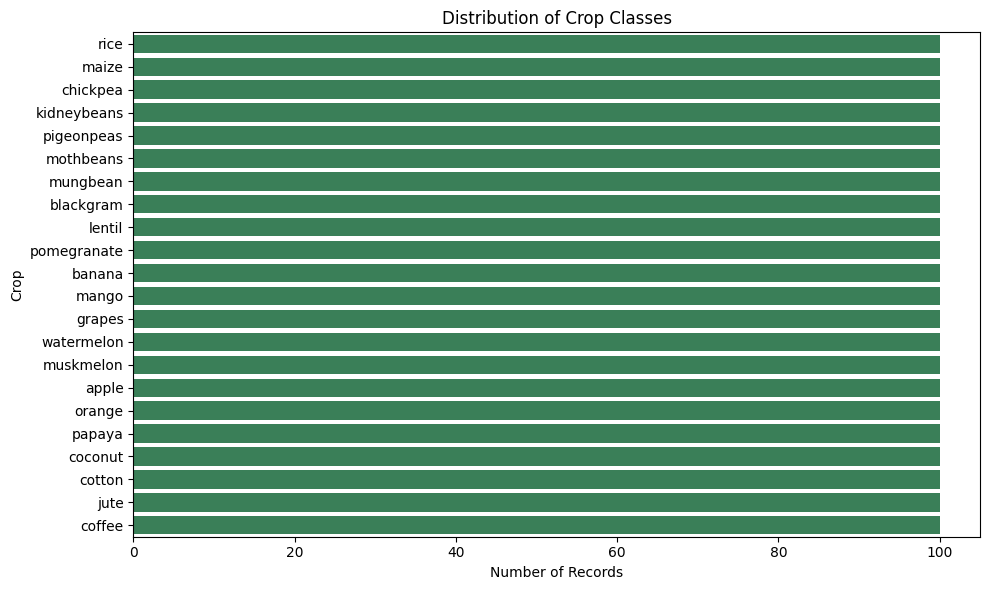

In [4]:
# SECTION 3: Data Exploration

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Dataset structure and data types
print("Dataset Information:")
df.info()

# 2. Summary statistics
print("\nSummary Statistics:")
display(df.describe())

# 3. Check data quality
print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# 4. Distribution of crop labels
crop_counts = df["label"].value_counts()

print("\nNumber of crop classes:", df["label"].nunique())
print("Records per crop:")
print(crop_counts)

# 5. Visualize crop distribution
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="label",
    order=crop_counts.index,
    color="seagreen"
)

plt.title("Distribution of Crop Classes")
plt.xlabel("Number of Records")
plt.ylabel("Crop")

plt.tight_layout()
plt.show()

In [ ]:
# SECTION 4: Data Preprocessing and Model Training

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Separate features and target
X = df.drop(columns=["label"])
y = df["label"]

# Encode crop names as numeric labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Scale features using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the Random Forest classifier
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_scaled, y_train)

print("Model training completed.")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

# Evaluate on the test set
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print(f"\nTest Accuracy: {accuracy:.2%}")
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=range(len(le.classes_)),
        target_names=le.classes_,
        zero_division=0
    )
)

Model training completed.
Training samples: 1760
Testing samples: 440

Test Accuracy: 99.55%

Classification Report:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon      

Test Accuracy: 99.55%
Correct predictions: 438 out of 440


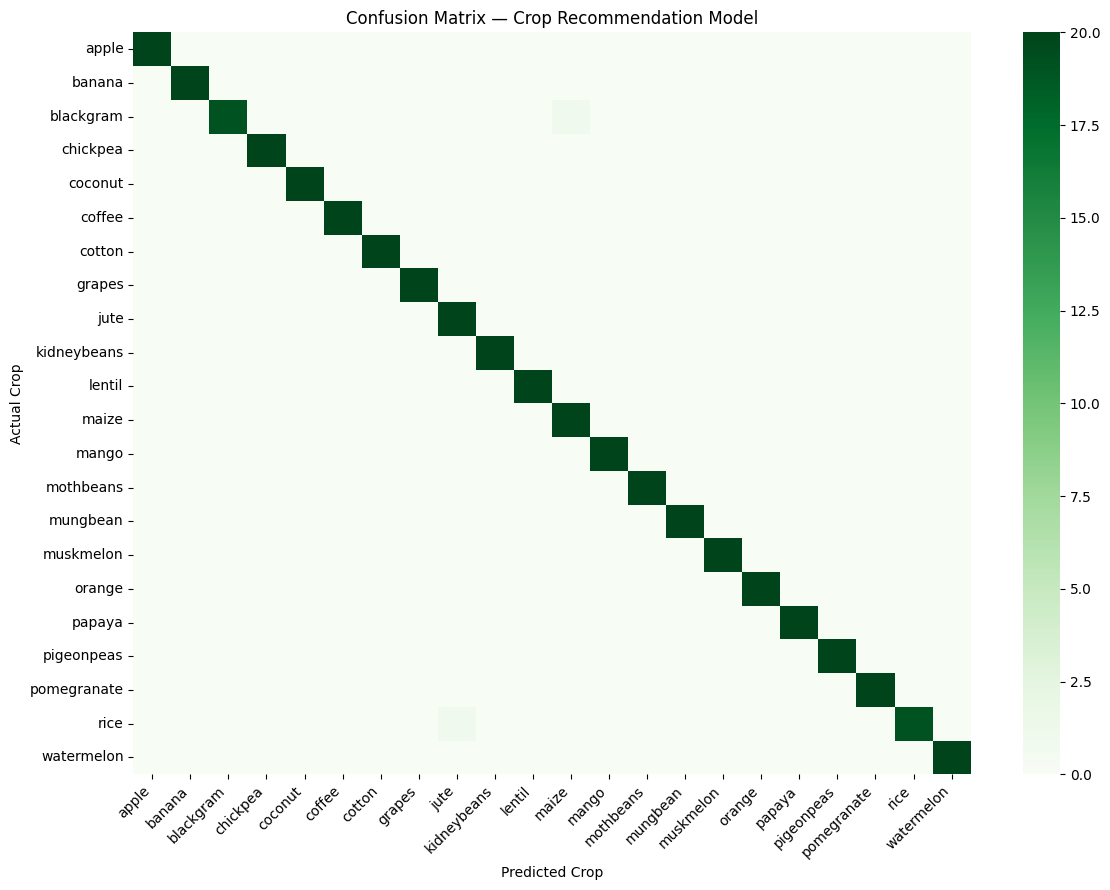

In [ ]:
# SECTION 5: Model Evaluation

from sklearn.metrics import confusion_matrix, accuracy_score

# Evaluate predictions on the test set
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.2%}")
print(f"Correct predictions: {(y_test == y_pred).sum()} out of {len(y_test)}")

# Generate the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(le.classes_))
)

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm,
    cmap="Greens",
    xticklabels=le.classes_,
    yticklabels=le.classes_,
    cbar=True
)

plt.title("Confusion Matrix — Crop Recommendation Model")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# SECTION 6: Crop Prediction for Custom Inputs

feature_names = [
    "N", "P", "K", "temperature",
    "humidity", "ph", "rainfall"
]

def predict_crop(N, P, K, temperature, humidity, ph, rainfall):
    """Predict a crop from soil nutrient and environmental values."""

    values = [N, P, K, temperature, humidity, ph, rainfall]

    # Basic input validation
    if any(value < 0 for value in values):
        raise ValueError("Input values cannot be negative.")

    if not 0 <= humidity <= 100:
        raise ValueError("Humidity must be between 0 and 100.")

    if not 0 <= ph <= 14:
        raise ValueError("Soil pH must be between 0 and 14.")

    # Arrange inputs in the same order used during training
    input_data = pd.DataFrame([values], columns=feature_names)

    # Apply the training scaler and predict the crop
    scaled_data = scaler.transform(input_data)
    prediction = model.predict(scaled_data)

    return le.inverse_transform(prediction)[0]


# Test the function with sample inputs
test_inputs = [
    [90, 42, 43, 20, 80, 6.5, 202],
    [40, 55, 60, 25, 70, 6.8, 120],
    [10, 30, 40, 35, 40, 5.5, 50]
]

print("Crop Recommendation Tests\n")

for i, values in enumerate(test_inputs, start=1):
    crop = predict_crop(*values)

    print(f"Test {i}")
    print(f"Input values: {values}")
    print(f"Recommended crop: {crop.title()}")
    print("-" * 40)

Crop Recommendation Tests

Test 1
Input values: [90, 42, 43, 20, 80, 6.5, 202]
Recommended crop: Rice
----------------------------------------
Test 2
Input values: [40, 55, 60, 25, 70, 6.8, 120]
Recommended crop: Papaya
----------------------------------------
Test 3
Input values: [10, 30, 40, 35, 40, 5.5, 50]
Recommended crop: Mango
----------------------------------------


In [ ]:
# SECTION 7: Save the Trained Model

import os
import joblib

# Bundle the model and preprocessing objects
model_package = {
    "model": model,
    "scaler": scaler,
    "label_encoder": le,
    "feature_names": feature_names
}

# Save the package
model_path = "/content/Final_crop_recommendation_model.pkl"
joblib.dump(model_package, model_path)

# Verify the saved file
if os.path.exists(model_path) and os.path.getsize(model_path) > 0:
    print("Model package saved successfully.")
    print(f"File size: {os.path.getsize(model_path) / 1024:.2f} KB")
else:
    raise RuntimeError("Model package was not saved correctly.")

Model package saved successfully.
File size: 3493.39 KB
